# Workshop 02

# YOLOv8 Object Detection Using Laptop Camera

## Aim
To capture an image using the laptop camera and perform object detection using YOLOv8.

## Step 1: Import Required Libraries

Import OpenCV, Matplotlib, YOLO, and other required libraries.

In [ ]:
import cv2

# Open the web camera
cap = cv2.VideoCapture(0)

# Background subtractor for foreground-object detection
bg_subtractor = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=50,
    detectShadows=True
)

while True:

    # Read frame from webcam
    ret, frame = cap.read()

    if not ret:
        print("Cannot read frame from web camera")
        break

    # Create foreground mask
    mask = bg_subtractor.apply(frame)

    # Remove small noise
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (5, 5)
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_DILATE,
        kernel
    )

    # Find contours of detected objects
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Process each detected contour
    for contour in contours:

        # Calculate contour area
        area = cv2.contourArea(contour)

        # Ignore very small regions
        if area > 2500:

            # Get bounding rectangle
            x, y, w, h = cv2.boundingRect(contour)

            # Draw bounding box
            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            # Display detection text
            cv2.putText(
                frame,
                "Object Detected",
                (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

    # Display camera frame
    cv2.imshow(
        "Workshop 2 - Object Detection",
        frame
    )

    # Press 'q' to stop
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# Release the webcam
cap.release()

# Close all OpenCV windows
cv2.destroyAllWindows()

Text(0.5, 1.0, 'OUTPUT IMAGE')

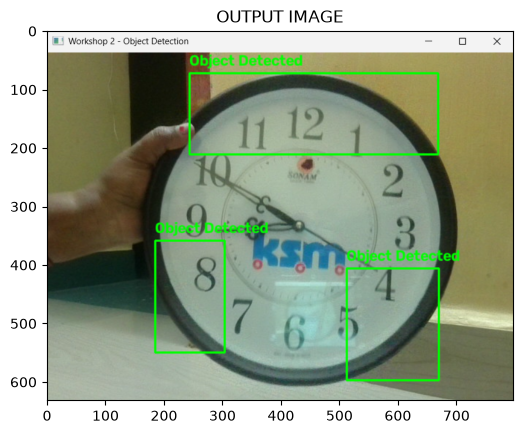

In [2]:
outputimage = cv2.imread("output.png")
plt.imshow(outputimage[:,:,::-1]);plt.title("OUTPUT IMAGE")